Loading taxis Dataset

First import seaborn and variable created as taxis and load the taxis dataset and print head and findout how many column in the taxis load data

In [1]:
import seaborn as sns

taxis = sns.load_dataset("taxis")
print(taxis.head())

               pickup             dropoff  passengers  distance  fare   tip  \
0 2019-03-23 20:21:09 2019-03-23 20:27:24           1      1.60   7.0  2.15   
1 2019-03-04 16:11:55 2019-03-04 16:19:00           1      0.79   5.0  0.00   
2 2019-03-27 17:53:01 2019-03-27 18:00:25           1      1.37   7.5  2.36   
3 2019-03-10 01:23:59 2019-03-10 01:49:51           1      7.70  27.0  6.15   
4 2019-03-30 13:27:42 2019-03-30 13:37:14           3      2.16   9.0  1.10   

   tolls  total   color      payment            pickup_zone  \
0    0.0  12.95  yellow  credit card        Lenox Hill West   
1    0.0   9.30  yellow         cash  Upper West Side South   
2    0.0  14.16  yellow  credit card          Alphabet City   
3    0.0  36.95  yellow  credit card              Hudson Sq   
4    0.0  13.40  yellow  credit card           Midtown East   

            dropoff_zone pickup_borough dropoff_borough  
0    UN/Turtle Bay South      Manhattan       Manhattan  
1  Upper West Side South      

Check for missing values in the dataset and identify columns with missing data.
Missing values in the datasheet using user defined variable missing count and missing pct and find the null value and adding column missing value equal the missing count value and print the output

In [3]:

import seaborn as sns
import pandas as pd

taxis = sns.load_dataset("taxis")
missing = pd.DataFrame({
    "missing_count": taxis.isnull().sum(),
    "missing_pct": (taxis.isnull().mean() * 100).round(2),
})

cols_with_missing = missing[missing["missing_count"] > 0]
print(cols_with_missing.sort_values("missing_count", ascending=False))

                 missing_count  missing_pct
dropoff_zone                45         0.70
dropoff_borough             45         0.70
payment                     44         0.68
pickup_zone                 26         0.40
pickup_borough              26         0.40


Impute missing values using appropriate strategies based on the column type (e.g., using mean, median, or mode for numerical columns, and mode for categorical columns).


Using variable taxis as the dataset copy to dataframe and variable number column and category column gives as column drop and category column using function as null by using for loop and if give the condition and print as missing before and missing after and get the output

In [4]:
taxis = sns.load_dataset("taxis")
df = taxis.copy()
num_cols = df.select_dtypes(include="number").columns
cat_cols = df.select_dtypes(exclude="number").columns.drop(["pickup", "dropoff"])
for col in cat_cols:
    if df[col].isnull().any():
        df[col] = df[col].fillna(df[col].mode()[0])

print("Missing before:", taxis.isnull().sum().sum())
print("Missing after: ", df.isnull().sum().sum())

Missing before: 186
Missing after:  0


Visualizations using Matplotlib/Pandas Plot

Plot a line chart to visualize the fare over time, using the pickup timestamp as the x-axis and fare as the y-axis. Ensure the pickup column is converted to a datetime format before plotting.


Import matplotlib.pyplot as plt and numpy as ny and pandas as py then give the create two variable and list stucture and label as x as fare and y as pickup and title label as line chart and get the output

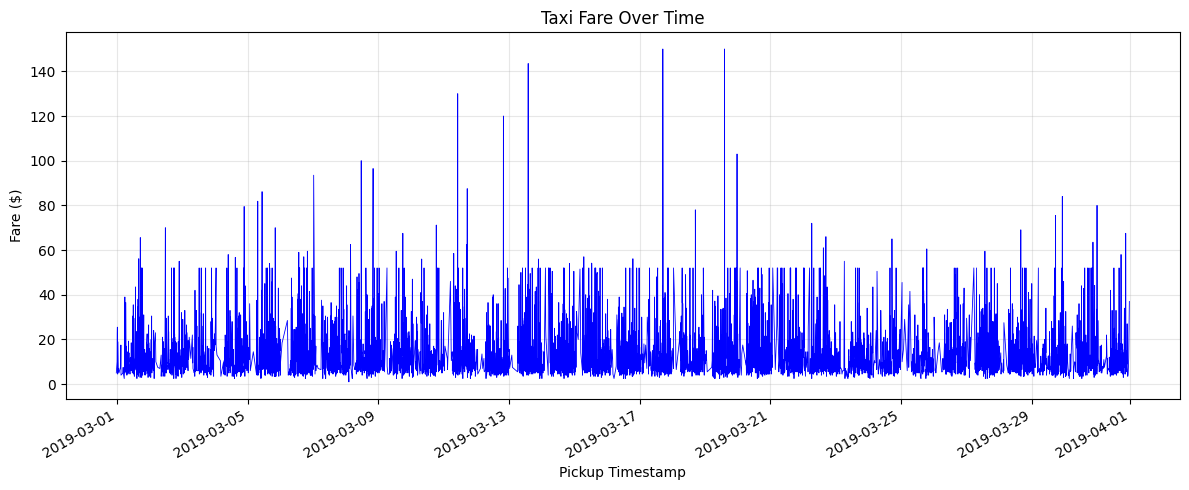

In [5]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

taxis["pickup"] = pd.to_datetime(taxis["pickup"])
df = taxis.sort_values("pickup")

fig, ax = plt.subplots(figsize=(12, 5))
df.plot(x="pickup", y="fare", kind="line", ax=ax, linewidth=0.6, color="blue", legend=False)
ax.set_title("Taxi Fare Over Time")
ax.set_xlabel("Pickup Timestamp")
ax.set_ylabel("Fare ($)")
ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

Create a bar chart to show the total fare for each pickup_borough. Group the data by pickup_borough and sum the fare for each group.

fare by borough as df, groupby as pickup borough and fare in build function as sort value figure function subplot as size of chart as 8 and 5 fare bu borough as kind bar ans give color as blue  title name as total fare by pickup and x axis as pickup borough and y axis as total fare using grid to y axis 0.3 and for loop as give the bar chart to centre and bottom to chart and get the output

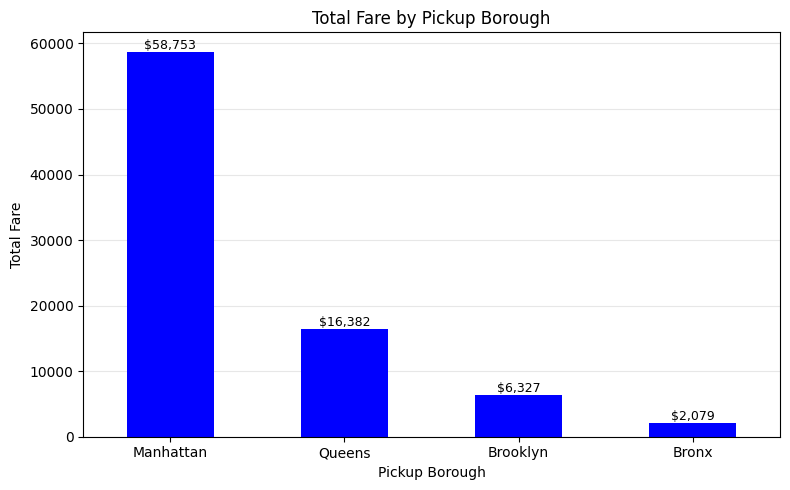

In [27]:
taxis = sns.load_dataset("taxis")

fare_by_borough = (
    taxis.groupby("pickup_borough")["fare"].sum().sort_values(ascending=False)
)
fig, ax = plt.subplots(figsize=(8, 5))
fare_by_borough.plot(kind="bar", ax=ax, color="blue")
ax.set_title("Total Fare by Pickup Borough")
ax.set_xlabel("Pickup Borough")
ax.set_ylabel("Total Fare")
ax.tick_params(axis="x", rotation=0)
ax.grid(axis="y", alpha=0.3)
ax.set_axisbelow(True)
for i, v in enumerate(fare_by_borough):
    ax.text(i, v, f"${v:,.0f}", ha="center", va="bottom", fontsize=9)
plt.tight_layout()
plt.show()

Plot a pie chart showing the distribution of trips based on the payment method (credit card, cash, etc.). Each slice should represent the count of trips for a specific payment method.

payment count as variable in payment in value.count and fig size give 6,6 and payment count plot kind function assign as pie color give ligtgreen and lightblue for creditcard and cash set the title as tip distribuition by payment ment, then layout and get the output

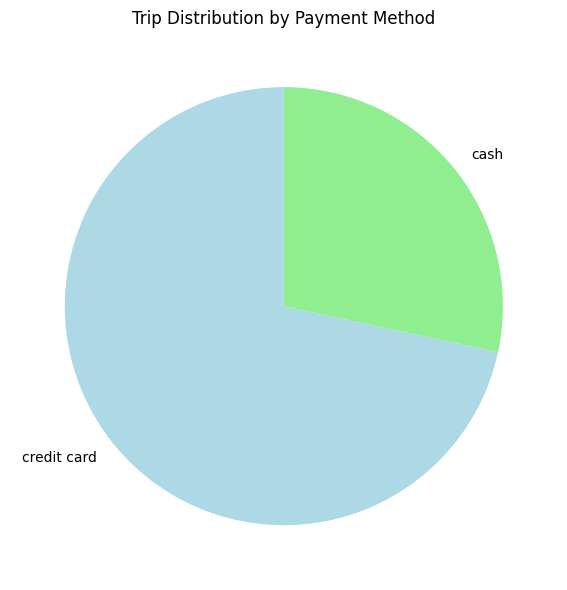

In [34]:
taxis = sns.load_dataset("taxis")
payment_counts = taxis["payment"].value_counts()
fig, ax = plt.subplots(figsize=(6, 6))
payment_counts.plot(
    kind="pie", ax=ax,startangle=90, colors=["lightblue", "lightgreen"]
)
ax.set_title("Trip Distribution by Payment Method")
ax.set_ylabel("")
plt.tight_layout()
plt.show()

Create a histogram to visualize the distribution of distance. Customize the number of bins for better granularity and ensure the plot is easy to interpret.

Here variable d assign as taxis distance and fig ax plt subplot give the figure as 10,5 and cap funtion assign the measure value .99 for the bar and trimmed function gives the variable less than cap function assgn the histogram background color as white and bar color as blue. Named the title as distribuition of trip distance xlabel as distance mile and ylabel as numnber o trips assign the grid unction use to grid for the chart and layout function and get the output.

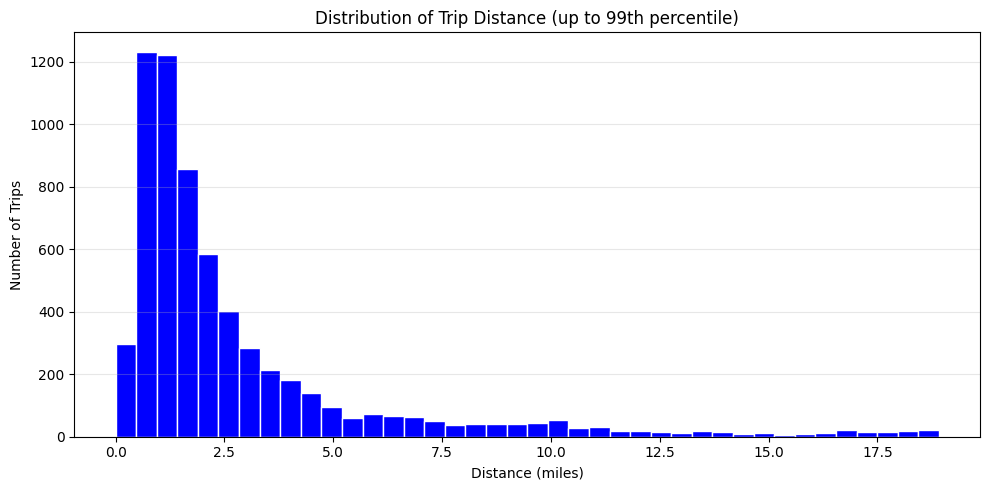

In [41]:
taxis = sns.load_dataset("taxis")
d = taxis["distance"]
fig, ax = plt.subplots(figsize=(10, 5))
cap = d.quantile(0.99)
trimmed = d[d <= cap]
ax.hist(trimmed, bins=40, color="blue", edgecolor="white")
ax.set_title("Distribution of Trip Distance (up to 99th percentile)")
ax.set_xlabel("Distance (miles)")
ax.set_ylabel("Number of Trips")
ax.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

Plot a box plot to visualize the distribution of tip amounts for each pickup_borough. Use pickup_borough as the categorical axis and tip as the numeric axis
Here the box plot dropna is used to the subset to pickup borough order group by contain to mean and sort value fig ax to plt subplot to size of the chart in box plot x axis is pickborough  and y axis tip color gives the box plot is green marksize is gives 3 and title gives tip amount by pickup borough and give the grid to box plot and layout function get the output

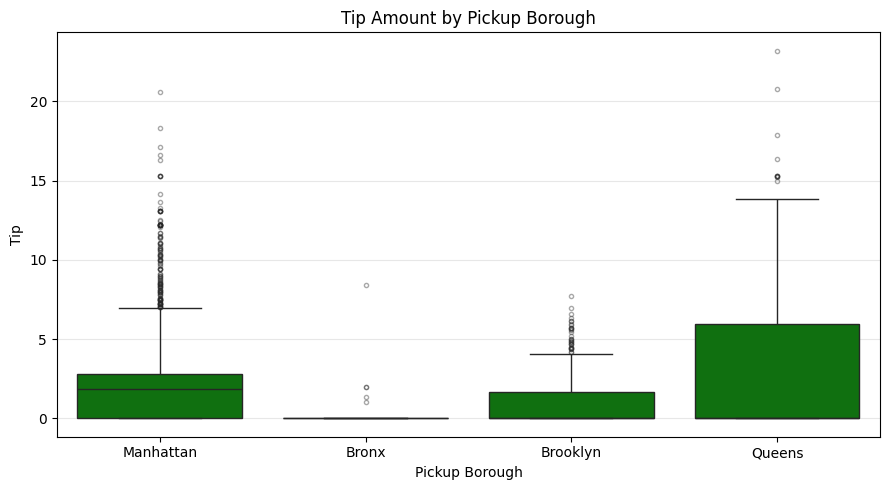

In [6]:
taxis = sns.load_dataset("taxis")
df = taxis.dropna(subset=["pickup_borough"])
order = df.groupby("pickup_borough")["tip"].median().sort_values(ascending=False).index
fig, ax = plt.subplots(figsize=(9, 5))
sns.boxplot(data=df, x="pickup_borough", y="tip", order=order, color="green",
            flierprops={"markersize": 3, "alpha": 0.4}, ax=ax)
ax.set_title("Tip Amount by Pickup Borough")
ax.set_xlabel("Pickup Borough")
ax.set_ylabel("Tip")
ax.grid(axis="y", alpha=0.3)
ax.set_axisbelow(True)
plt.tight_layout()
plt.show()

Create a count plot to visualize the number of trips in each pickup_borough. The x-axis should represent the boroughs, and the y-axis should show the count of trips

In count plot visualization variable order to pickup borough to value count of index and figure size is set to 8,5 countplot x axis assign to pickup borough and y axis number of trip grid is set to the chart here for loop take to ax container for bar label layout function and get the output

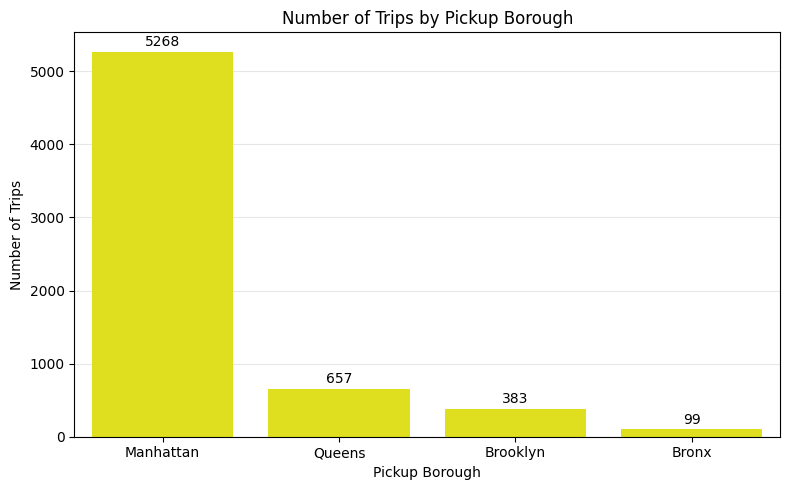

In [8]:
taxis = sns.load_dataset("taxis")
order = taxis["pickup_borough"].value_counts().index

fig, ax = plt.subplots(figsize=(8, 5))
sns.countplot(data=taxis, x="pickup_borough", order=order, color="yellow", ax=ax)
ax.set_title("Number of Trips by Pickup Borough")
ax.set_xlabel("Pickup Borough")
ax.set_ylabel("Number of Trips")
ax.grid(axis="y", alpha=0.3)
ax.set_axisbelow(True)
for c in ax.containers:
    ax.bar_label(c, padding=2)
plt.tight_layout()
plt.show()

Plot a scatter plot to show the relationship between distance and fare. Use distance on the x-axis and fare on the y-axis to visualize any correlation. Color the points based on the pickup_borough to differentiate the trips by their respective boroughs.


 In Scatter plot dataframe dropna function to subset pickup borough order is assingn to list four place fig size is 10,6 scatterplot x axis assign to distance and y axis assign to fare hue function used order title is given are vs distance title as legend set the axisbelow boolean liyout function and get the output  

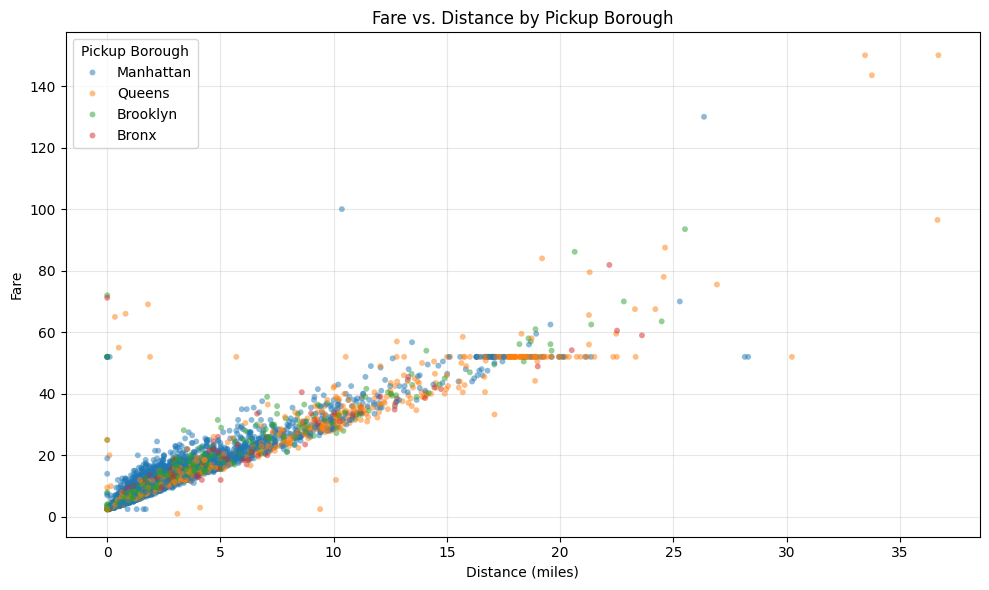

In [18]:
taxis = sns.load_dataset("taxis")
df = taxis.dropna(subset=["pickup_borough"])

order = ["Manhattan", "Queens", "Brooklyn", "Bronx"]

fig, ax = plt.subplots(figsize=(10, 6))
sns.scatterplot(data=df, x="distance", y="fare", hue="pickup_borough", hue_order=order,
                alpha=0.5, s=18, edgecolor="none", ax=ax)
ax.set_title("Fare vs. Distance by Pickup Borough")
ax.set_xlabel("Distance (miles)")
ax.set_ylabel("Fare")
ax.legend(title="Pickup Borough")
ax.grid(alpha=0.3)
ax.set_axisbelow(True)
plt.tight_layout()
plt.show()


Create a pair plot to visualize the pairwise relationships between distance, fare, tip, and total. Color the data points according to the pickup_zone method to compare how different zones affect these variables.

In pair plot visualize variable topzone assign the value count head and index dataframe pickup is assign to topzones variable g assign to pairplot df variable is add to four integer  hue function is used to pickupzone to top of the list. Five zone for the pickup g.figure.suptitle to show the four output and get the output

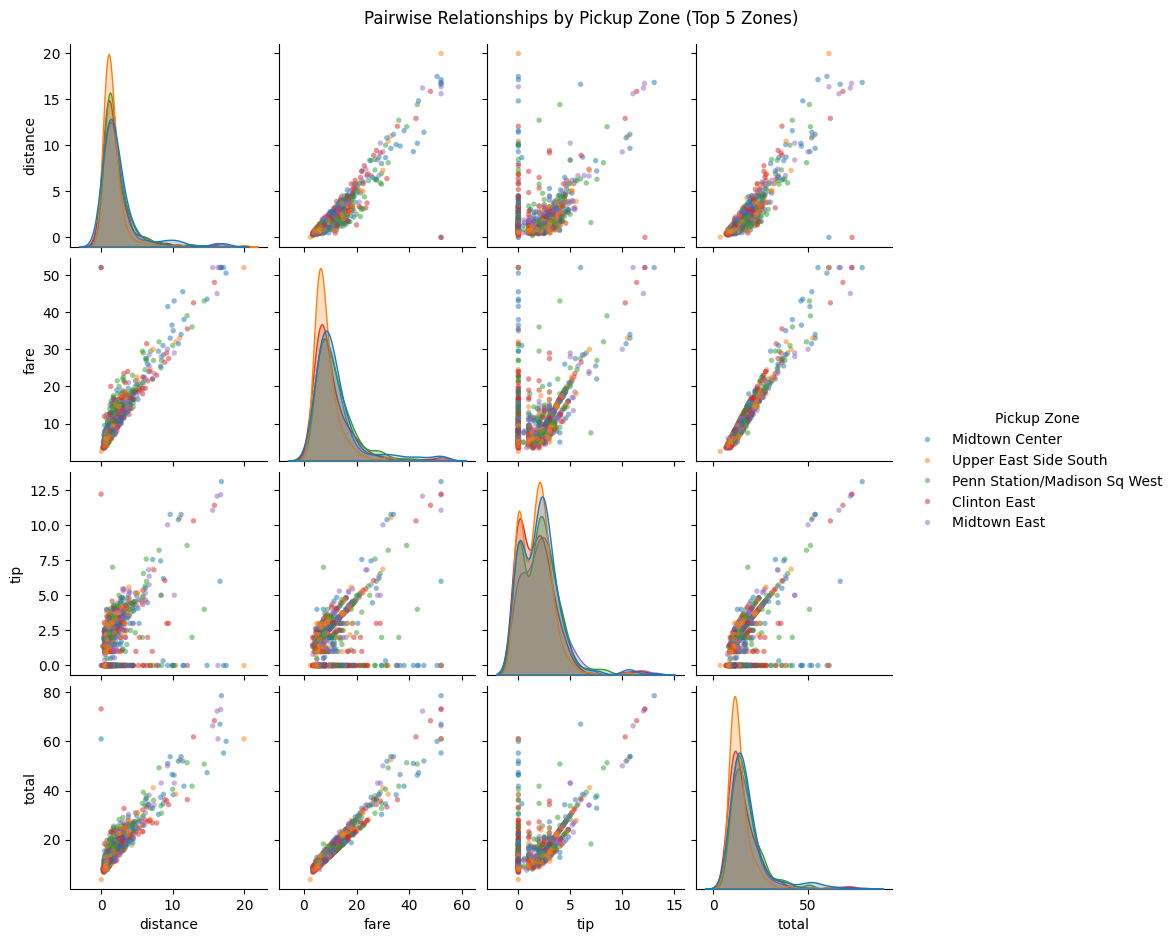

In [9]:
taxis = sns.load_dataset("taxis")
top_zones = taxis["pickup_zone"].value_counts().head(5).index
df = taxis[taxis["pickup_zone"].isin(top_zones)]
g = sns.pairplot(
    df, vars=["distance", "fare", "tip", "total"],
    hue="pickup_zone", hue_order=list(top_zones),
    diag_kind="kde",
    plot_kws={"alpha": 0.5, "s": 15, "edgecolor": "none"},
    height=2.3,
)
g.figure.suptitle("Pairwise Relationships by Pickup Zone (Top 5 Zones)", y=1.02)
g.legend.set_title("Pickup Zone")
plt.show()

Plot a violin plot to show the distribution of fare for each payment method. Use the payment method as the categorical axis and fare as the numeric axis to visualize its distribution.

Voilin plot chart shown the dropna subset to payment and fig plt.subplot give size of the chart assign pink and orange for the cash and credit, Both the axis have the quartile distance shown in figure.title is shown fare distribuiton by payment and x axis payment menthod and y axis is set axis below is true layout function and get the output to show

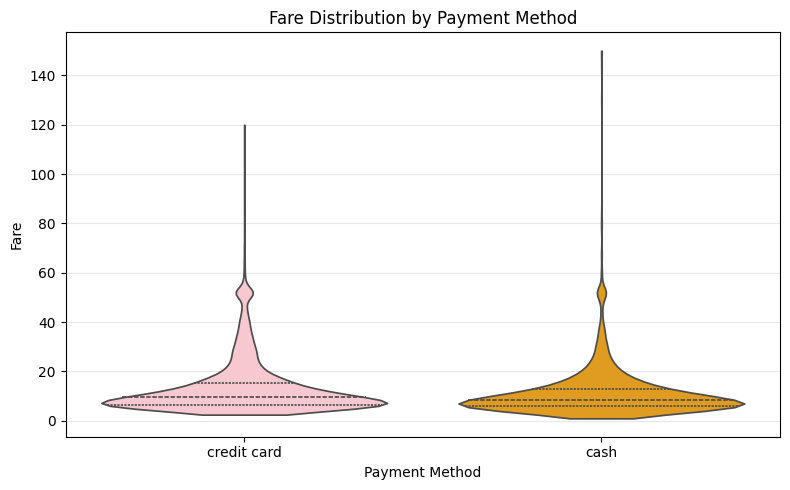

In [10]:
taxis = sns.load_dataset("taxis")
df = taxis.dropna(subset=["payment"])

fig, ax = plt.subplots(figsize=(8, 5))
sns.violinplot(data=df, x="payment", y="fare", hue="payment",
               palette=["pink", "orange"], inner="quartile", cut=0,
               legend=False, ax=ax)
ax.set_title("Fare Distribution by Payment Method")
ax.set_xlabel("Payment Method")
ax.set_ylabel("Fare")
ax.grid(axis="y", alpha=0.3)
ax.set_axisbelow(True)
plt.tight_layout()
plt.show()